In [1]:
import sys
print(sys.executable)

/Users/dimitris/Desktop/Projects/PremierLeague/pl-xg-luck/.venv/bin/python


In [2]:
from datetime import date
from understatapi import UnderstatClient
import pandas as pd

def get_season(season):
    with UnderstatClient() as understat:
        teams = understat.league(league="EPL").get_team_data(season=season)

    rows = []
    for team_id, team_info in teams.items():
        team_name = team_info['title']

        for match in team_info['history']:
            row = {'team':team_name, **match, 'season':season}
            rows.append(row)

    df = pd.DataFrame(rows)
    return df

    
df_now = get_season("2026")            # 2026 = season 2026/27
today = date.today().isoformat()       # e.g. "2026-10-12"

df_now.to_csv(f"epl_2026_as_of_{today}.csv", index=False)
print(df_now.shape) #118%20!=0 so probably 2 teams havent played yet(they are playing today 12/10/2026)

(160, 21)


In [3]:
games = df_now["team"].value_counts().sort_values()
print(games)

team
Aston Villa          8
Everton              8
Bournemouth          8
Sunderland           8
Crystal Palace       8
Chelsea              8
Tottenham            8
Arsenal              8
Newcastle United     8
Liverpool            8
Manchester City      8
Manchester United    8
Hull                 8
Brighton             8
Fulham               8
Brentford            8
Leeds                8
Nottingham Forest    8
Ipswich              8
Coventry             8
Name: count, dtype: int64


In [4]:
#Same logic with Session 1 but now we measure 'games' which calculates how many games each team has played
now = df_now.groupby("team").agg(
    games = ("pts","count"),
    pts = ("pts","sum"),
    xpts = ("xpts", "sum"),
    scored=("scored", "sum"),
    missed=("missed", "sum"),
)
now["gd"] = now["scored"]-now["missed"]
now = now.sort_values(["pts", "gd"], ascending=False)
now["cur_rank"] = range(1, 21)

now["luck"] = now["pts"] - now["xpts"]
now["pts_per_game"] = now["pts"]/now["games"]
now["xpts_per_game"] = now["xpts"]/now["games"]

now = now.sort_values("luck", ascending = False)
print(now.round(2))

                   games  pts   xpts  scored  missed  gd  cur_rank  luck  \
team                                                                       
Arsenal                8   21  15.96      13       5   8         2  5.04   
Manchester City        8   21  17.02      20       9  11         1  3.98   
Newcastle United       8   11   7.45      12      14  -2         8  3.55   
Liverpool              8   15  11.79      11       8   3         4  3.21   
Ipswich                8   10   7.12      12      16  -4        12  2.88   
Chelsea                8   13  10.22      17      15   2         5  2.78   
Aston Villa            8   11   8.30       9      12  -3         9  2.70   
Hull                   8   10   7.73       9       8   1        10  2.27   
Brighton               8   16  15.21      23       7  16         3  0.79   
Leeds                  8   11  10.90       9       6   3         7  0.10   
Brentford              8   11  11.35      14       9   5         6 -0.35   
Everton     

In [5]:
print(now.sort_values("xpts_per_game", ascending=False)[["pts_per_game", "xpts_per_game"]].round(2))

                   pts_per_game  xpts_per_game
team                                          
Manchester City            2.62           2.13
Arsenal                    2.62           1.99
Brighton                   2.00           1.90
Nottingham Forest          0.75           1.90
Bournemouth                1.12           1.86
Liverpool                  1.88           1.47
Brentford                  1.38           1.42
Fulham                     1.00           1.39
Leeds                      1.38           1.36
Everton                    1.25           1.35
Tottenham                  1.12           1.34
Manchester United          0.88           1.29
Chelsea                    1.62           1.28
Sunderland                 0.62           1.22
Aston Villa                1.38           1.04
Crystal Palace             0.88           1.02
Coventry                   0.75           1.01
Hull                       1.25           0.97
Newcastle United           1.38           0.93
Ipswich      

# **Note:** Nottingham Forest, Newcastle and Aston Villa stand out, for different reasons:

## **Nottingham Forest:**
By quality (xPts per game) it's 3rd, behind only Arsenal and City.
In the actual table, with just 5 points, it sits around 14th–15th. This is the biggest gap
in the league, making Forest the clearest candidate to climb.

## **Newcastle:**
The opposite case. By quality it's last (0.86 xPts per game), yet it already
has 8 points and sits mid-table. The most likely candidate to drop.

## **Aston Villa:**
Two things are happening at once:
- Last season's luck is gone: from +14 to −0.75 so far. Regression to the mean in action.
- Quality has dropped too: from 1.34 xPts per game last season (51 in 38 games) to 0.96 now,
  so Villa is genuinely playing worse, not just less lucky.

After only 6 games, part of these differences could still be noise.

In [6]:
now["games_left"] = 38 - now["games"]

now["proj_naive"] = now["pts"] + now["pts_per_game"] * now["games_left"]
now["proj_xpts"] = now["pts"] + now["xpts_per_game"] * now["games_left"]
now['diff'] = now["proj_xpts"] - now["proj_naive"]

now["proj_rank"] = now["proj_xpts"].rank(ascending=False, method="first").astype(int)  

now = now.sort_values("proj_xpts", ascending=False)
print(now[["pts", "proj_naive", "proj_xpts", "diff"]].round(1))



                   pts  proj_naive  proj_xpts  diff
team                                               
Manchester City     21        99.8       84.8 -14.9
Arsenal             21        99.8       80.8 -18.9
Brighton            16        76.0       73.1  -2.9
Bournemouth          9        42.8       64.7  22.0
Nottingham Forest    6        28.5       62.9  34.4
Liverpool           15        71.2       59.2 -12.0
Brentford           11        52.2       53.6   1.3
Leeds               11        52.2       51.9  -0.4
Chelsea             13        61.8       51.3 -10.4
Everton             10        47.5       50.5   3.0
Fulham               8        38.0       49.6  11.6
Tottenham            9        42.8       49.1   6.4
Manchester United    7        33.2       45.7  12.4
Aston Villa         11        52.2       42.1 -10.1
Sunderland           5        23.8       41.5  17.8
Hull                10        47.5       39.0  -8.5
Newcastle United    11        52.2       38.9 -13.3
Crystal Pala

### Projection: where will teams finish?

Two projections of final points, both keeping the points already earned:
- **Naive:** current points + remaining games × points per game so far ("same pace as now")
- **xPts-based:** current points + remaining games × xPts per game so far

Session 4 showed that xPts so far predicts remaining points better than the table at almost
every stage, so the xPts-based projection is the one we trust more. `diff` = xPts projection −
naive projection: positive means we expect the team to do better from here, negative worse.

**Expected to climb:**
- **Nottingham Forest** (+34): 14th–15th now, projected 4th. The biggest gap in the league.
- **Bournemouth, Fulham, Tottenham, Sunderland** (+24 to +34): all near the bottom now, but
  their xPts suggest they should get out of trouble.

**Expected to slow down:**
- **Manchester City and Arsenal** (−34, −16): their current pace isn't sustainable (the naive
  projection gives City 114 points), but they're still projected 1st and 2nd. Their *pace*
  drops, not their *position*.
- **Newcastle** (−10): 11th now with 8 points, projected 16th. One game (a loss to
  Coventry) moved this projection by 4 points and 2 places — a reminder of how noisy
  6-game samples are.
- **Hull, Chelsea, Ipswich** (−12 to −16): mid-table now, projected lower half.

**Limitations:**
- Only 6 games played. At this stage xPts predicts remaining points with r ≈ 0.67:
  better than the table, but far from certain. The projections are probably too extreme
  in both directions.
- Schedule isn't taken into account: a team that has already faced the top sides may have
  lower xPts than it deserves.
- Last season is ignored. Since quality persists year to year (r = 0.76), a stronger model
  would combine this season's xPts with last season's.

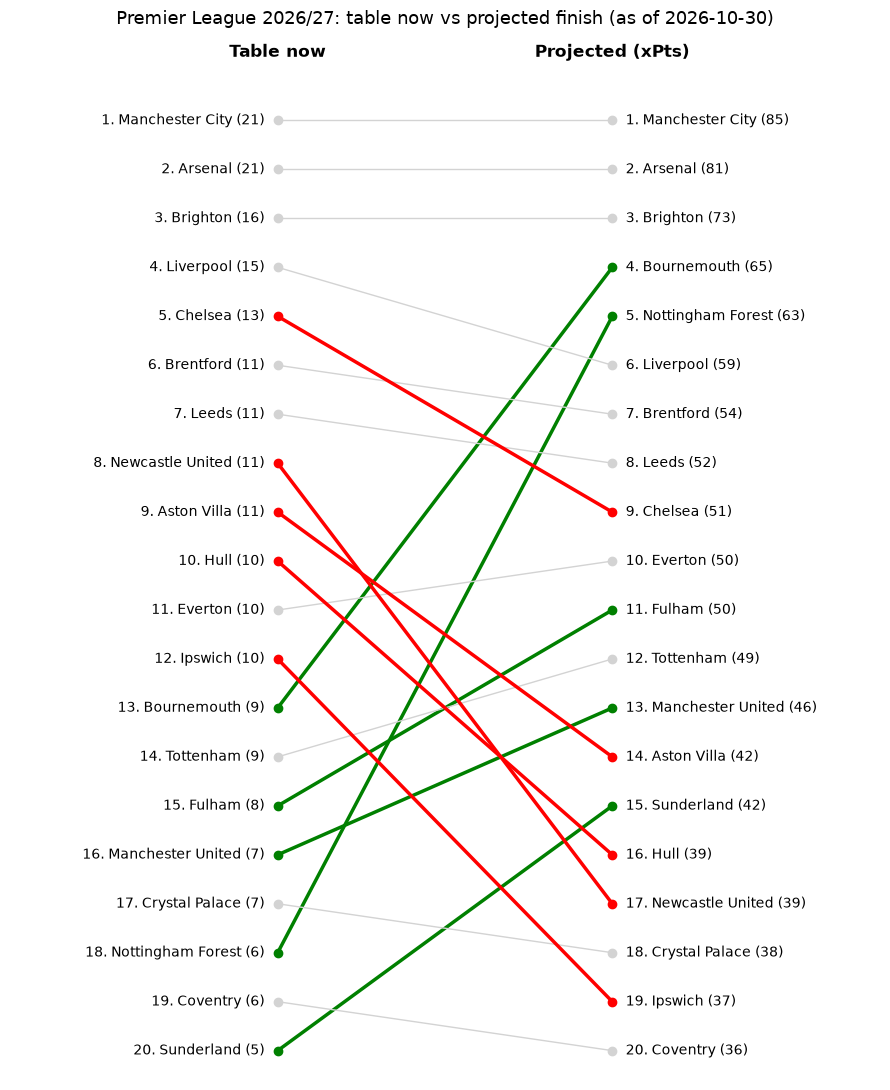

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 11))

for team, row in now.iterrows():
    move = row["cur_rank"] - row["proj_rank"]        
    if move >= 3:
        color, lw = "green", 2.5
    elif move <= -3:
        color, lw = "red", 2.5
    else:
        color, lw = "lightgrey", 1

    ax.plot([0, 1], [row["cur_rank"], row["proj_rank"]], color=color, linewidth=lw, marker="o")
    ax.text(-0.04, row["cur_rank"], f"{int(row['cur_rank'])}. {team} ({int(row['pts'])})",
        ha="right", va="center", fontsize=10)
    ax.text(1.04, row["proj_rank"], f"{int(row['proj_rank'])}. {team} ({row['proj_xpts']:.0f})",
        ha="left", va="center", fontsize=10)

ax.text(0, -0.3, "Table now", ha="center", fontweight="bold", fontsize=12)
ax.text(1, -0.3, "Projected (xPts)", ha="center", fontweight="bold", fontsize=12)

ax.set_xlim(-0.8, 1.8)
ax.set_ylim(20.6, -0.8)          # αντίστροφα: η 1η θέση πάνω
ax.axis("off")                   # χωρίς άξονες, μόνο οι γραμμές και τα ονόματα
ax.set_title(f"Premier League 2026/27: table now vs projected finish (as of {today})", fontsize=13)

plt.tight_layout()
plt.savefig(f"slope_{today}.png", dpi=150)
plt.show()

In [8]:
print(now[["pts", "proj_naive", "proj_xpts", "diff"]].round(1))

                   pts  proj_naive  proj_xpts  diff
team                                               
Manchester City     21        99.8       84.8 -14.9
Arsenal             21        99.8       80.8 -18.9
Brighton            16        76.0       73.1  -2.9
Bournemouth          9        42.8       64.7  22.0
Nottingham Forest    6        28.5       62.9  34.4
Liverpool           15        71.2       59.2 -12.0
Brentford           11        52.2       53.6   1.3
Leeds               11        52.2       51.9  -0.4
Chelsea             13        61.8       51.3 -10.4
Everton             10        47.5       50.5   3.0
Fulham               8        38.0       49.6  11.6
Tottenham            9        42.8       49.1   6.4
Manchester United    7        33.2       45.7  12.4
Aston Villa         11        52.2       42.1 -10.1
Sunderland           5        23.8       41.5  17.8
Hull                10        47.5       39.0  -8.5
Newcastle United    11        52.2       38.9 -13.3
Crystal Pala

In [9]:
locked = pd.read_csv("projection_table_2026-10-13.csv", index_col="team")

compare = locked[["pts", "proj_xpts", "proj_rank"]].join(
    now[["pts", "proj_xpts", "cur_rank", "proj_rank"]], lsuffix="_oct13", rsuffix="_now"
)
compare["pts_gained"] = compare["pts_now"] - compare["pts_oct13"]

print(compare.sort_values("pts_gained", ascending=False).round(1))

                   pts_oct13  proj_xpts_oct13  proj_rank_oct13  pts_now  \
team                                                                      
Arsenal                   15             78.9                2       21   
Fulham                     2             38.4               18        8   
Bournemouth                3             52.9                9        9   
Liverpool                  9             54.6                7       15   
Aston Villa                5             35.7               19       11   
Tottenham                  3             44.1               14        9   
Manchester City           18             80.5                1       21   
Brighton                  13             72.7                3       16   
Chelsea                   10             48.5               12       13   
Newcastle United           8             40.4               16       11   
Leeds                      9             50.9               10       11   
Nottingham Forest        

In [10]:
table = now.sort_values(["pts", "gd"], ascending=False).reset_index()
table.insert(0, "Pos", range(1, len(table) + 1))     

table = table[["Pos", "team", "games", "pts", "gd", "xpts"]].rename(columns={
    "team": "Team", "games": "P", "pts": "Pts", "gd": "GD", "xpts": "xPts",
})

table.style.hide(axis="index") \
    .format({"xPts": "{:.1f}"}) \
    .background_gradient(subset=["Pts","xPts"], cmap="Greens")

Pos,Team,P,Pts,GD,xPts
1,Manchester City,8,21,11,17.0
2,Arsenal,8,21,8,16.0
3,Brighton,8,16,16,15.2
4,Liverpool,8,15,3,11.8
5,Chelsea,8,13,2,10.2
6,Brentford,8,11,5,11.3
7,Leeds,8,11,3,10.9
8,Newcastle United,8,11,-2,7.4
9,Aston Villa,8,11,-3,8.3
10,Hull,8,10,1,7.7


In [11]:
villa = df_now[df_now["team"] == "Aston Villa"].sort_values("date")
print(villa[["date", "h_a", "scored", "missed", "xG", "xGA", "pts", "xpts"]].tail(5))

                  date h_a  scored  missed        xG       xGA  pts    xpts
3  2026-09-12 14:00:00   h       1       2  1.087860  2.794510    0  0.3503
4  2026-09-19 11:30:00   a       3       2  1.709200  1.721770    3  1.3685
5  2026-10-10 14:00:00   h       2       2  1.838420  1.281280    1  1.7818
6  2026-10-17 16:30:00   a       1       0  2.082200  0.920183    3  2.2166
7  2026-10-24 11:30:00   h       2       1  0.645964  2.285420    3  0.3320


# Aston villa:

Aston Villa's actual performance seems like it does not correspond to the prediction. The team is playing good, has Champions League appearances and is doing also good there. It's time to move to V2


### Blending this season with last season (shrinkage)

After only a few games, this season's xPts per game is noisy (see Session 4).
Last season's quality is a strong guide (year-to-year r = 0.76, Session 3).
So we combine the two.

**Idea: "virtual games".** Before the season, each team gets K virtual games,
each worth its average xPts per game from last season. We then add the real
games played this season and take the average of all of them:

    blend = (xPts this season + K × last season's xPts per game) / (games played + K)

- Numerator: total xPts (real + virtual)
- Denominator: total games (real + virtual)

**Example:** 8 games with 9.0 xPts (1.125/game), last season 1.34/game, K = 10:
(9.0 + 10 × 1.34) / (8 + 10) = 22.4 / 18 ≈ 1.24 → between this season and last.

**The weight shifts automatically:** this season counts for games / (games + K).
- 8 games → 44% this season, 56% last season
- 20 games → 67% / 33%
- 30 games → 75% / 25%

Early on we trust last season more; as games accumulate, this season takes over.

**K** = how many games' worth of trust we give last season. Higher K means the model
changes its mind more slowly. K = 10 is an assumption, not a tested value. It could
be tuned with a backtest on past seasons (try K = 5, 10, 20 and compare accuracy).

**Promoted teams** have no Premier League data from last season, so they use this
season's rate only (`fillna`). A possible improvement: use the average of past
promoted teams as their prior.

In [12]:
hist = pd.read_csv("epl_2014_2025_team_matches.csv")
last = hist[hist["season"] == 2025].groupby("team")["xpts"].mean()   # xPts per match last year

now["xpts_pg_last"] = last.reindex(now.index)
prior = now["xpts_pg_last"].fillna(now["xpts_per_game"])            # νεοφώτιστες: μόνο φετινά

K = 10    # πόσα "ματς αξίας" δίνουμε στην περσινή σεζόν
now["xpts_pg_blend"] = (now["xpts"] + K * prior) / (now["games"] + K)
now["proj_blend"] = now["pts"] + now["xpts_pg_blend"] * now["games_left"]

print(now[["pts", "proj_xpts", "proj_blend"]].sort_values("proj_blend", ascending=False).round(1))

                   pts  proj_xpts  proj_blend
team                                         
Arsenal             21       80.8        82.6
Manchester City     21       84.8        81.8
Brighton            16       73.1        65.6
Liverpool           15       59.2        61.6
Bournemouth          9       64.7        60.2
Chelsea             13       51.3        55.8
Brentford           11       53.6        55.0
Leeds               11       51.9        53.9
Manchester United    7       45.7        52.5
Nottingham Forest    6       62.9        49.8
Tottenham            9       49.1        48.4
Everton             10       50.5        48.2
Newcastle United    11       38.9        47.5
Aston Villa         11       42.1        47.2
Fulham               8       49.6        46.3
Crystal Palace       7       37.7        44.3
Sunderland           5       41.5        39.7
Hull                10       39.0        39.0
Ipswich             10       36.7        36.7
Coventry             6       36.4 